# Tunable metasurfaces: from voltage to a checked response

Read the [chapter](../chapters/07-active-tunable.md), [worked guide](../chapters/07-tunable-guide.md), and [lab](../labs/07-tunable-lab.md). Restart and run every cell. These are an effective passive one-port RLC model, a prescribed scalar aperture, synthetic feedback, and a slowly varying modulation envelope. No patch geometry has been solved or measured. The [model drawing](../assets/chapter-07/tunable-cell.svg) identifies what each approximation represents.

## 1. Parameters and reproducibility

Use $e^{-i\omega t}$. The reference is 10 GHz, normal incidence, no transmitted port, and a positive real air reference impedance. Effective circuit values are teaching parameters; they are not a diode datasheet or an extraction from the drawing. Every array uses 32 elements at half the 10-GHz wavelength. Changing a circuit parameter defines a new experiment and requires fresh checks.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
import hashlib, json, platform, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd()/'simulations').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from simulations.tunable_surface import *
P=Surface()
FREQUENCY_GHZ=10.
TARGET_DEG=25.
VOLTAGE=np.linspace(0,P.voltage_max_V,401)
FREQUENCIES=np.linspace(7.,13.,241)
ANGLES=np.linspace(-80.,80.,641)
plt.rcParams.update({'figure.dpi':115,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('Python',platform.python_version(),'NumPy',np.__version__)
print(json.dumps(asdict(P),indent=2))
print('Equivalent circuit + scalar array + synthetic feedback; no full-wave or measured data.')

Python 3.12.1 NumPy 2.4.6
{
  "inductance_nH": 20.0,
  "capacitance0_pF": 0.12,
  "junction_voltage_V": 1.0,
  "exponent": 1.0,
  "resistance_ohm": 25.0,
  "impedance_ohm": 376.730313668,
  "voltage_max_V": 20.0
}
Equivalent circuit + scalar array + synthetic feedback; no full-wave or measured data.


## 2. Trace the reachable complex response

**Predict:** does a voltage increase move the resonance up or down? Does 16 equally spaced voltages mean 16 equally spaced phases?

The model uses $C(V)=C_0/(1+V/V_j)^M$, $Z_s=R+i(1/\omega C-\omega L)$, and $\Gamma=(Z_s-Z_0)/(Z_s+Z_0)$. Its independent dissipative fraction is $A=4RZ_0/|Z_s+Z_0|^2$. The phase is undefined at zero reflection; do not unwrap through a zero and call the jump a useful tuning range. The default $R=25\,\Omega$ avoids that singularity.

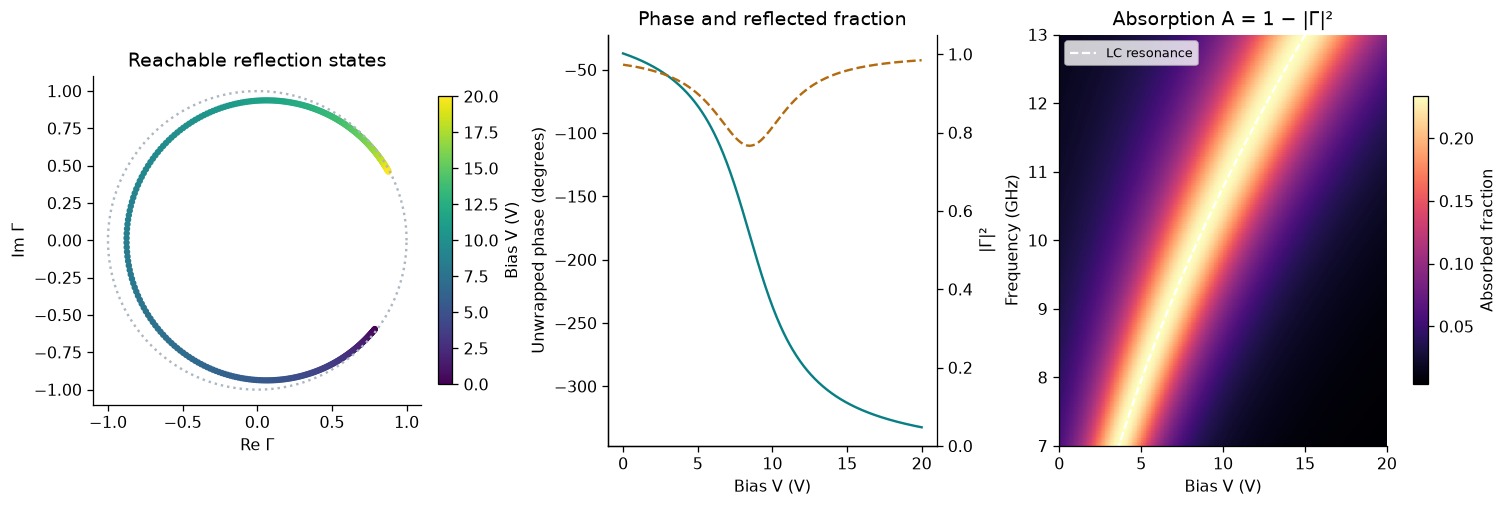

Continuous phase span at 10 GHz: 295.273 degrees
Minimum sampled reflection fraction: 0.766583


In [2]:
sweep=response(FREQUENCY_GHZ,VOLTAGE,P)
phase=np.rad2deg(np.unwrap(np.angle(sweep['gamma'])))
spectral=response(FREQUENCIES[:,None],VOLTAGE[None,:],P)
assert np.max(abs(spectral['reflected']+spectral['absorbed']-1))<2e-15
resonance_GHz=1/(2*np.pi*np.sqrt(P.inductance_nH*1e-9*capacitance(VOLTAGE,P)))/1e9
fig,axes=plt.subplots(1,3,figsize=(13,4.3),constrained_layout=True)
unit=np.exp(1j*np.linspace(0,2*np.pi,400))
axes[0].plot(unit.real,unit.imag,':',color='#abb8c2')
sc=axes[0].scatter(sweep['gamma'].real,sweep['gamma'].imag,c=VOLTAGE,s=9,cmap='viridis')
axes[0].set(xlabel='Re Γ',ylabel='Im Γ',title='Reachable reflection states',aspect='equal',xlim=(-1.1,1.1),ylim=(-1.1,1.1))
fig.colorbar(sc,ax=axes[0],label='Bias V (V)',shrink=.7)
axes[1].plot(VOLTAGE,phase,color='#087f83');axes[1].set(xlabel='Bias V (V)',ylabel='Unwrapped phase (degrees)',title='Phase and reflected fraction')
power_axis=axes[1].twinx();power_axis.plot(VOLTAGE,sweep['reflected'],color='#b36b10',ls='--');power_axis.set(ylabel='|Γ|²',ylim=(0,1.05));power_axis.spines['right'].set_visible(True)
im=axes[2].pcolormesh(VOLTAGE,FREQUENCIES,spectral['absorbed'],shading='auto',cmap='magma')
axes[2].plot(VOLTAGE,resonance_GHz,'w--',lw=1.4,label='LC resonance');axes[2].set(xlabel='Bias V (V)',ylabel='Frequency (GHz)',ylim=(7,13),title='Absorption A = 1 − |Γ|²');axes[2].legend(fontsize=8)
fig.colorbar(im,ax=axes[2],label='Absorbed fraction',shrink=.7)
plt.show()
print(f'Continuous phase span at 10 GHz: {abs(phase[-1]-phase[0]):.3f} degrees')
print(f'Minimum sampled reflection fraction: {sweep["reflected"].min():.6f}')

## 3. Program a finite scalar aperture

With positions $x_j/\lambda_0$, the target samples are $d_j=e^{i2\pi(x_j/\lambda_0)\sin\theta_t}$. Select the codeword minimizing $|\Gamma_b-d_j|^2$ at each site. This is a stated local rule, not a globally optimal beamformer. The field is $F(\theta)=N^{-1}\sum_j\Gamma_j e^{-i2\pi(x_j/\lambda_0)\sin\theta}$.

Compare ideal phase states with 16 equally spaced voltages from the actual circuit. Keep the common normalization: $I=|F|^2$ is the intensity relative to the ideal coherent $N$-source reference, **not total efficiency or directivity**. Do not renormalize every curve to its own peak. The phase-error sinc estimate assumes uniformly distributed errors; a finite deterministic ramp can differ. One-bit coding can create a second equally strong beam.

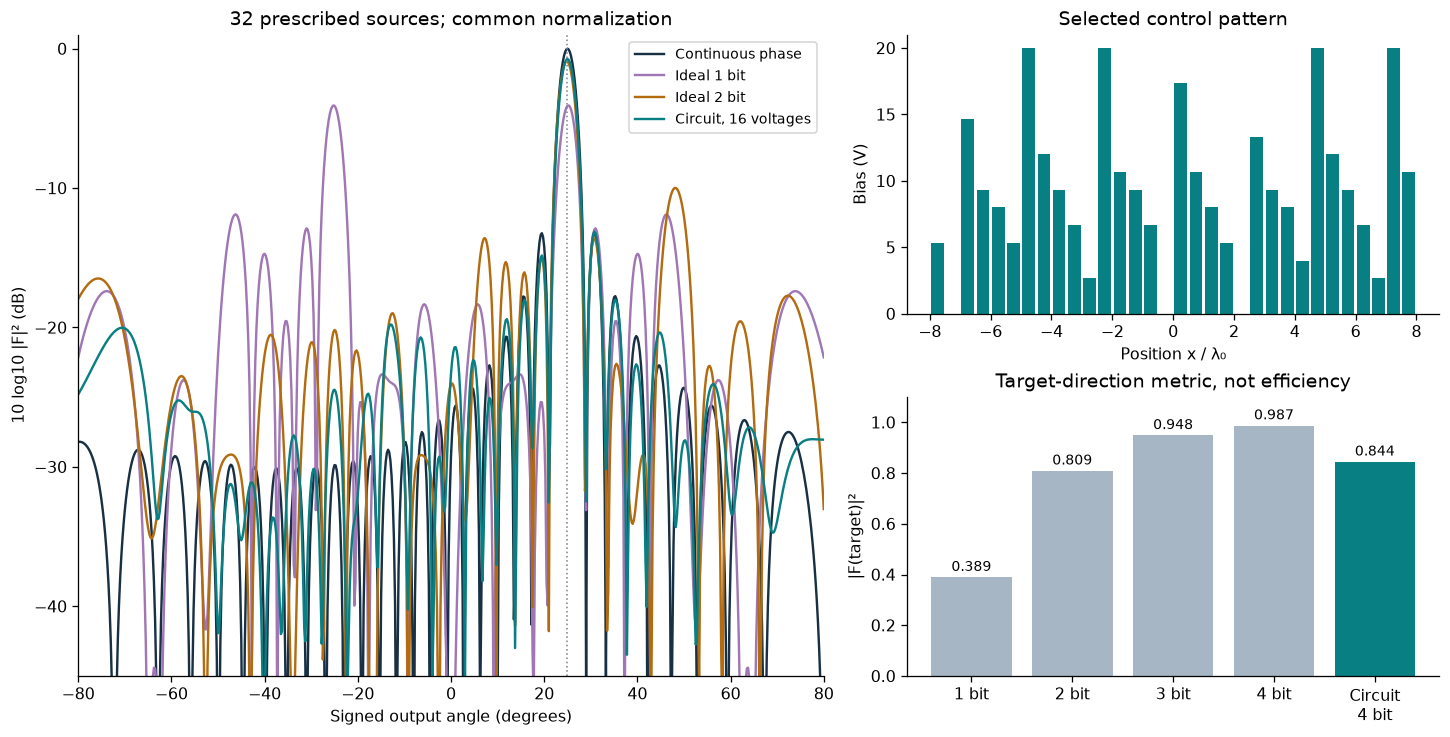

{'1': 0.389047, '2': 0.808605, '3': 0.948344, '4': 0.986783}
Circuit target metric: 0.8440039160100381


In [3]:
x=array_positions()
ideal=np.exp(2j*np.pi*x*np.sin(np.deg2rad(TARGET_DEG)))
designs={str(b):code_array(TARGET_DEG,b) for b in range(1,5)}
actual=code_array(TARGET_DEG,4,circuit=True)
fig=plt.figure(figsize=(12.5,6.3),layout='constrained');gs=fig.add_gridspec(2,2,width_ratios=[1.4,1])
ax=fig.add_subplot(gs[:,0])
for label,g,color in [('Continuous phase',ideal,'#173044'),('Ideal 1 bit',designs['1']['gamma'],'#a077b4'),('Ideal 2 bit',designs['2']['gamma'],'#b36b10'),('Circuit, 16 voltages',actual['gamma'],'#087f83')]:
    ax.plot(ANGLES,10*np.log10(np.maximum(abs(array_field(g,ANGLES,x))**2,1e-6)),label=label,color=color)
ax.axvline(TARGET_DEG,color='#7c8993',ls=':',lw=1);ax.set(xlabel='Signed output angle (degrees)',ylabel='10 log10 |F|² (dB)',ylim=(-45,1),xlim=(-80,80),title='32 prescribed sources; common normalization');ax.legend(fontsize=9)
ax=fig.add_subplot(gs[0,1]);ax.bar(x,actual['voltage_V'],width=.42,color='#087f83');ax.set(xlabel='Position x / λ₀',ylabel='Bias (V)',title='Selected control pattern')
ax=fig.add_subplot(gs[1,1]);vals=[designs[str(b)]['target_metric'] for b in range(1,5)]+[actual['target_metric']]
ax.bar(['1 bit','2 bit','3 bit','4 bit','Circuit\n4 bit'],vals,color=['#a6b6c4']*4+['#087f83']);ax.set(ylabel='|F(target)|²',ylim=(0,1.1),title='Target-direction metric, not efficiency')
for i,v in enumerate(vals):ax.text(i,v+.025,f'{v:.3f}',ha='center',fontsize=9)
plt.show()
print({k:round(v['target_metric'],6) for k,v in designs.items()})
print('Circuit target metric:',actual['target_metric'])

## 4. Close the loop using a measured complex response

The synthetic plant has $C_0$ 12% above the nominal value. The controller does not receive that parameter: it queries the plant's complex reflection, scans 17 voltages, and refines the best bracket. Its target is the nominal response at 8 V. Keep every query, including poor ones. This noiseless example demonstrates sensing and adjustment; it does not establish robustness to sensor noise, hysteresis, coupling, or changing loads.

**Independent check:** equal capacitance requires $1+V_\mathrm{corrected}/V_j=1.12(1+8/V_j)$ for $M=1$, hence $V_\mathrm{corrected}=9.08$ V. Compare this algebraic result with the controller.

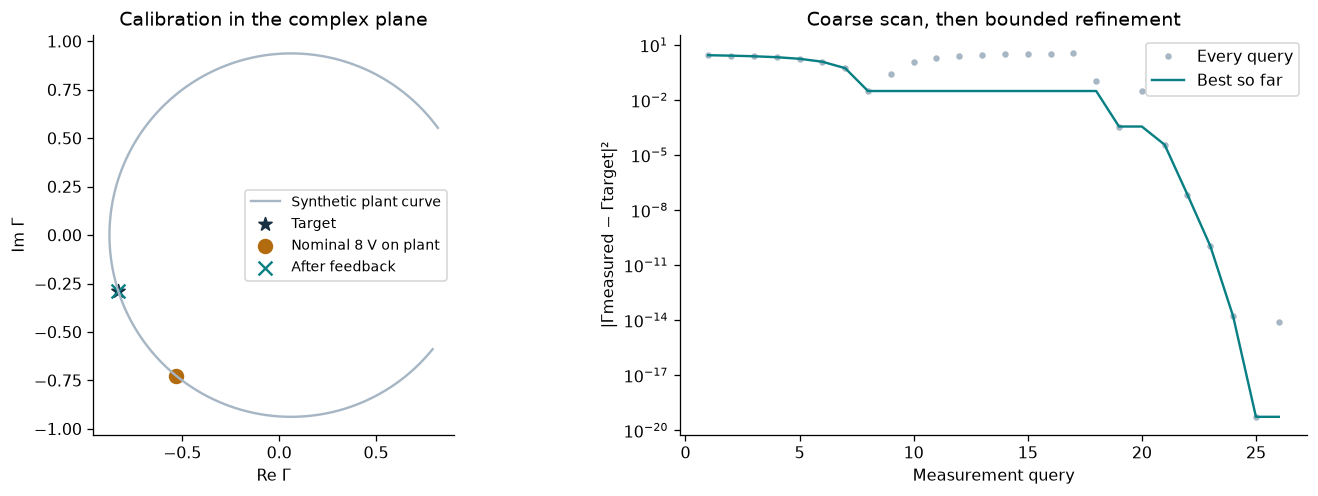

Before: complex error 0.532803; after: 2.302e-10
Corrected bias: 9.08000000 V; 26 noiseless response queries


In [4]:
plant=replace(P,capacitance0_pF=P.capacitance0_pF*1.12)
target=complex(response(10.,8.,P)['gamma'])
feedback=feedback_voltage(target,lambda v:response(10.,v,plant)['gamma'])
chosen=feedback['selected']['voltage_V'];before=complex(response(10.,8.,plant)['gamma']);after=complex(response(10.,chosen,plant)['gamma'])
assert abs(chosen-9.08)<1e-5
fig,axes=plt.subplots(1,2,figsize=(11.8,4.2),constrained_layout=True)
plant_curve=response(10.,VOLTAGE,plant)['gamma']
axes[0].plot(plant_curve.real,plant_curve.imag,color='#a6b6c4',label='Synthetic plant curve')
for value,label,color,marker in [(target,'Target','#173044','*'),(before,'Nominal 8 V on plant','#b36b10','o'),(after,'After feedback','#087f83','x')]:axes[0].scatter(value.real,value.imag,label=label,color=color,s=75,marker=marker)
axes[0].set(xlabel='Re Γ',ylabel='Im Γ',aspect='equal',title='Calibration in the complex plane');axes[0].legend(fontsize=9)
costs=np.array([q['error_squared'] for q in feedback['queries']])
axes[1].semilogy(np.arange(1,len(costs)+1),np.maximum(costs,1e-20),'.',color='#a6b6c4',label='Every query')
axes[1].semilogy(np.arange(1,len(costs)+1),np.maximum(np.minimum.accumulate(costs),1e-20),color='#087f83',label='Best so far')
axes[1].set(xlabel='Measurement query',ylabel='|Γmeasured − Γtarget|²',title='Coarse scan, then bounded refinement');axes[1].legend()
plt.show()
print(f'Before: complex error {abs(before-target):.6f}; after: {abs(after-target):.3e}')
print(f'Corrected bias: {chosen:.8f} V; {len(costs)} noiseless response queries')

## 5. A changing command is not an instantaneous electromagnetic state

The bias obeys $\tau\dot V+V=V_\mathrm{command}$ with $\tau=4\,\mu\mathrm s$. A step settles to 2% of its voltage change after $-\tau\ln(0.02)$. Reflection is nonlinear in voltage, so phase does not follow the same exponential.

For a periodic command (20 kHz, 50% duty), compare instantaneous binary states with the steady periodic RC state. Expand $\Gamma(t)=\sum_\ell c_\ell e^{-i\ell\Omega t}$; the reflected carrier has frequencies $\omega_0+\ell\Omega$. A binary waveform has $c_\ell=(\Gamma_a-\Gamma_b)D\operatorname{sinc}(\ell D)e^{i\pi\ell D}+\Gamma_b\delta_{\ell0}$. The plotted $|c_\ell|^2$ are envelope spectral weights. A modulated electromagnetic power budget additionally needs pump exchange, material dispersion, port normalization, and all sidebands. This slow-envelope model does not solve that budget.

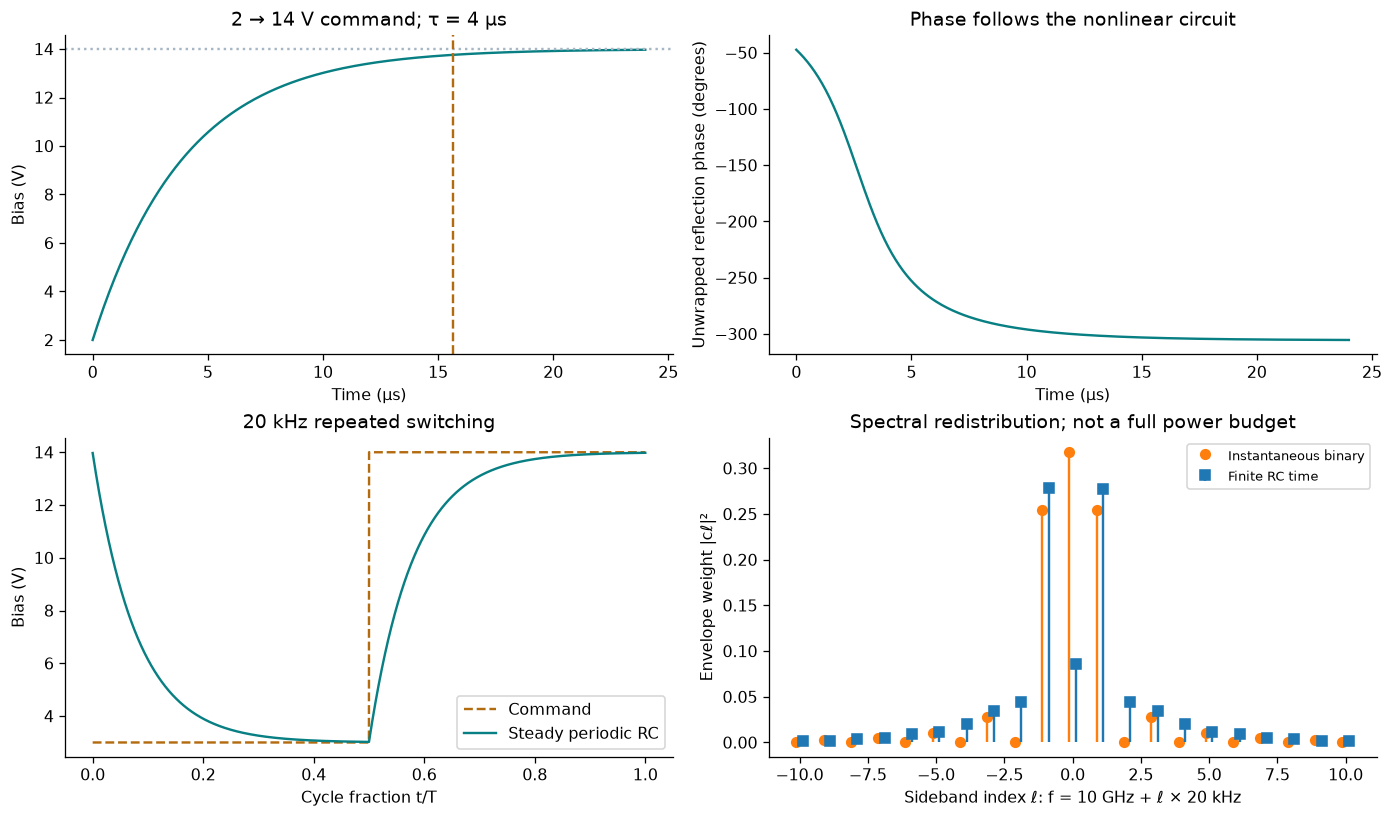

2% voltage settling time (μs): 15.648092021712584
Full sampled-envelope Parseval residual: 2.220446049250313e-16


In [5]:
time=np.linspace(0,24e-6,301);bias=step_voltage(time);step=response(10.,bias,P)
u=(np.arange(8192)+.5)/8192;orders=np.arange(-10,11)
period_bias=periodic_voltage(u);slow=response(10.,period_bias,P)['gamma']
ga,gb=response(10.,[3.,14.],P)['gamma'];fast=binary_harmonics(orders,ga,gb)
slow_coeff=sampled_harmonics(slow,orders)
assert np.max(abs(sampled_harmonics(np.where(u<.5,ga,gb),orders)-fast))<1e-6
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
axes[0,0].plot(time*1e6,bias,color='#087f83');axes[0,0].axhline(14,color='#a6b6c4',ls=':');axes[0,0].axvline(-4*np.log(.02),color='#b36b10',ls='--');axes[0,0].set(xlabel='Time (μs)',ylabel='Bias (V)',title='2 → 14 V command; τ = 4 μs')
axes[0,1].plot(time*1e6,np.rad2deg(np.unwrap(np.angle(step['gamma']))),color='#087f83');axes[0,1].set(xlabel='Time (μs)',ylabel='Unwrapped reflection phase (degrees)',title='Phase follows the nonlinear circuit')
axes[1,0].plot(u,np.where(u<.5,3,14),color='#b36b10',ls='--',label='Command');axes[1,0].plot(u,period_bias,color='#087f83',label='Steady periodic RC');axes[1,0].set(xlabel='Cycle fraction t/T',ylabel='Bias (V)',title='20 kHz repeated switching');axes[1,0].legend()
axes[1,1].stem(orders-.12,abs(fast)**2,linefmt='C1-',markerfmt='C1o',basefmt=' ',label='Instantaneous binary');axes[1,1].stem(orders+.12,abs(slow_coeff)**2,linefmt='C0-',markerfmt='C0s',basefmt=' ',label='Finite RC time')
axes[1,1].set(xlabel='Sideband index ℓ: f = 10 GHz + ℓ × 20 kHz',ylabel='Envelope weight |cℓ|²',title='Spectral redistribution; not a full power budget');axes[1,1].legend(fontsize=8)
plt.show()
print('2% voltage settling time (μs):',-4*np.log(.02))
print('Full sampled-envelope Parseval residual:',abs(np.sum(abs(np.fft.ifft(slow))**2)-np.mean(abs(slow)**2)))

## 6. Audit and save the browser reference

The independent audit solves the impedance boundary equations, integrates the RC differential equation, compares direct harmonic quadrature with an FFT, checks analytical binary coefficients, and rejects invalid inputs. Its declared default reference does not certify an edited experiment. The browser selects saved results from the same generator; no browser-lab download control is provided.

**Exercises:** replace the uniform-voltage codebook by phase-aware voltages; introduce noisy measurements and report repeatability; change the capacitance law and test whether the target is reachable; identify when modulation is too fast for a frozen-state model. A full-wave biased cell, an array with coupling, and hardware feedback are the next validation stages.

In [6]:
from scripts.validate_chapter07 import validate
audit=validate();assert audit['status']=='passed'
def curve(f):
    z=response(f,VOLTAGE,P)
    return dict(frequency_GHz=f,real=z['gamma'].real.tolist(),imag=z['gamma'].imag.tolist(),
                reflected=z['reflected'].tolist(),phase=np.rad2deg(np.unwrap(np.angle(z['gamma']))).tolist())
beam_cases=[]
for target_angle in range(-40,41,5):
    variants=[]
    for label,bits,circuit_flag in [('ideal1',1,False),('ideal2',2,False),('ideal4',4,False),('circuit4',4,True)]:
        d=code_array(float(target_angle),bits,circuit_flag)
        variants.append(dict(key=label,intensity=(abs(array_field(d['gamma'],ANGLES,d['positions']))**2).tolist(),
                             voltage=d['voltage_V'].tolist() if circuit_flag else None,indices=d['indices'].tolist(),target_metric=d['target_metric']))
    beam_cases.append(dict(target_deg=target_angle,variants=variants))
reference=dict(metadata=dict(schema='tunable-surface-v1',source_sha256=audit['source_sha256'],parameters=asdict(P),evidence='analytical/synthetic only'),
               voltage=VOLTAGE.tolist(),cell_curves=[curve(float(f)) for f in range(7,14)],angles=ANGLES.tolist(),beams=beam_cases,
               feedback=feedback,dynamics=dict(time_us=(time*1e6).tolist(),voltage=bias.tolist(),phase=np.rad2deg(np.unwrap(np.angle(step['gamma']))).tolist(),
               cycle=u[::16].tolist(),period_voltage=period_bias[::16].tolist(),orders=orders.tolist(),fast_weights=(abs(fast)**2).tolist(),slow_weights=(abs(slow_coeff)**2).tolist()))
path=ROOT/'data/chapter-07/reference.json';path.parent.mkdir(parents=True,exist_ok=True)
path.write_text(json.dumps(reference,separators=(',',':'),allow_nan=False)+'\n',encoding='utf-8')
print(json.dumps(audit['checks'],indent=2));print('Saved data/chapter-07/reference.json')

{
  "power_balance": 8.881784197001252e-16,
  "boundary_solution": 4.002966042486721e-16,
  "quantization_integral": 1.0471978839632989e-10,
  "RC_ODE": 2.7714719408322708e-11,
  "binary_harmonics": 3.4009594624229706e-08,
  "FFT_parity": 1.8041124150158794e-16,
  "Parseval": 0.0,
  "invalid_inputs": 9
}
Saved data/chapter-07/reference.json
